# 02 · Modelagem: prever quem vai cancelar

**Objetivo:** dar ao time de retenção uma lista de clientes ordenada por risco de cancelamento.

**Como eu evito me enganar:**
- separo **20% da base para teste** logo no início, e só uso essa parte uma vez, no final;
- comparo os modelos com **validação cruzada de 5 dobras** apenas na parte de treino;
- todo o pré-processamento fica **dentro do Pipeline**, para não vazar informação do teste para o treino.

O código está em `src/churn/` e este notebook usa as mesmas funções do script `python -m churn.train`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from churn.data import load_clean, split_xy

pd.set_option("display.max_columns", 30)

In [2]:
from sklearn.model_selection import train_test_split

from churn.config import RANDOM_STATE, TEST_SIZE

df = load_clean()
X, y = split_xy(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
print(f"Treino: {len(X_train)} clientes · Teste: {len(X_test)} clientes")
print(f"Churn no treino: {y_train.mean():.1%} · no teste: {y_test.mean():.1%}")

Treino: 5634 clientes · Teste: 1409 clientes
Churn no treino: 26.5% · no teste: 26.5%


`stratify=y` garante a mesma proporção de churn nos dois pedaços.

## 1. Pré-processamento

- **Numéricas** (`tenure`, `MonthlyCharges`, `TotalCharges`): preenche faltantes com a mediana e padroniza (média 0, desvio 1).
- **Categóricas** (16 colunas): one-hot. `handle_unknown="ignore"` evita erro se surgir uma categoria nova em produção.

In [3]:
from churn.features import build_preprocessor

prep = build_preprocessor().fit(X_train)
print(f"{X_train.shape[1]} colunas originais viram {len(prep.get_feature_names_out())} depois do one-hot")

19 colunas originais viram 46 depois do one-hot


## 2. Modelos candidatos

Comparo um **baseline** (sempre chuta "não cancela"), uma **Regressão Logística**, um **Random Forest** e um **Gradient Boosting**. Todos com `class_weight="balanced"`, que dá mais peso à classe minoritária (quem cancela).

In [4]:
from churn.train import compare_models

cv = compare_models(X_train, y_train)
cv[["modelo", "roc_auc", "roc_auc_std", "pr_auc", "recall", "precision", "f1"]].round(3)

,modelo,roc_auc,roc_auc_std,pr_auc,recall,precision,f1
0,Regressão Logística,0.846,0.012,0.660,0.801,0.517,0.628
1,Random Forest,0.845,0.009,0.653,0.762,0.540,0.632
2,Gradient Boosting,0.841,0.009,0.657,0.769,0.536,0.631
3,Baseline (classe mais comum),0.500,0.000,0.265,0.000,0.000,0.000


**Leitura:**
- O baseline tem ROC-AUC 0,50 (chute) e recall 0: não encontra ninguém.
- Os três modelos de verdade ficam **empatados**: a diferença de ROC-AUC entre eles é menor que o desvio entre as dobras (cerca de 0,01).

Com empate, escolho o **mais simples e explicável**: a Regressão Logística. Cada coeficiente diz quanto uma característica aumenta ou diminui o risco, o que o time de negócio consegue entender e questionar.

In [5]:
from churn.train import choose_model

escolhido = choose_model(cv)
escolhido

'Regressão Logística'

## 3. Avaliação final no teste

Agora, e só agora, uso os 20% separados no início.

In [6]:
from sklearn.base import clone

from churn.models import candidates
from churn.train import evaluate

modelo = clone(candidates()[escolhido]).fit(X_train, y_train)
proba = modelo.predict_proba(X_test)[:, 1]
m = evaluate(y_test, proba)
print(f"ROC-AUC: {m['roc_auc']:.3f}")
print(f"PR-AUC:  {m['pr_auc']:.3f}  (referência: taxa de churn = {y_test.mean():.3f})")
print(f"Recall:  {m['recall']:.1%}  dos que cancelaram foram sinalizados")
print(f"Precisão: {m['precision']:.1%}  dos sinalizados realmente cancelaram")
print(f"Top 20% de maior risco concentram {m['churn_capturado_top20pct']:.1%} de todos os churns")
m["confusion_matrix"]

ROC-AUC: 0.842
PR-AUC:  0.633  (referência: taxa de churn = 0.265)
Recall:  78.3%  dos que cancelaram foram sinalizados
Precisão: 50.4%  dos sinalizados realmente cancelaram
Top 20% de maior risco concentram 49.7% de todos os churns


{'tn': 747, 'fp': 288, 'fn': 81, 'tp': 293}

O resultado no teste (ROC-AUC 0,84) bate com a validação cruzada (0,85): o modelo **não decorou o treino**.

**O que isso significa para o negócio:** se o time de retenção ligar só para os 20% de clientes com maior risco, alcança cerca de metade de todos que iam cancelar, contra 20% se escolhesse ao acaso.

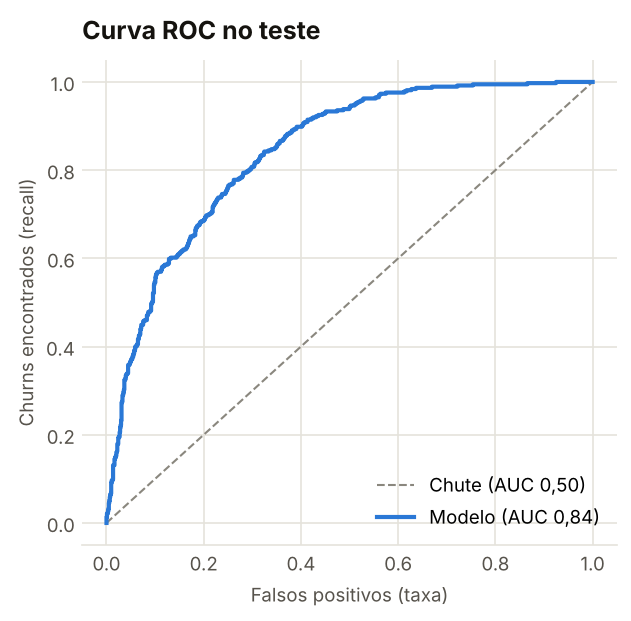

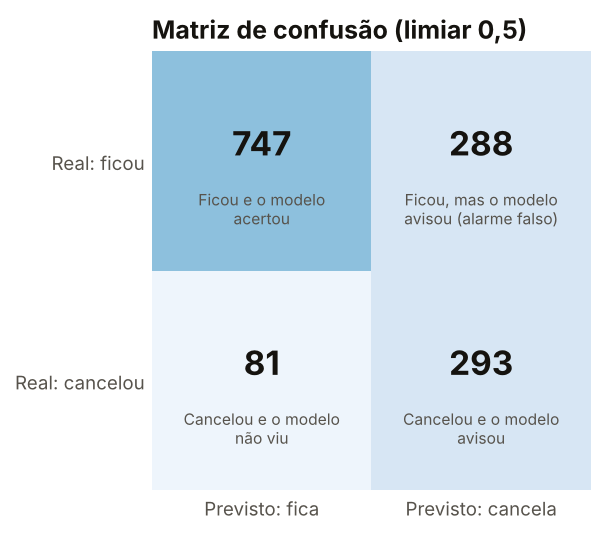

In [7]:
from churn.plots import save_all
from churn.config import FIGURES_DIR
from IPython.display import Image, display

save_all(df, modelo, X_test, y_test, m, FIGURES_DIR)
for nome in ["curva_roc.png", "matriz_de_confusao.png"]:
    display(Image(FIGURES_DIR / nome, width=420))

## 4. Escolha do limiar

Com limiar 0,5, o modelo encontra 78% dos churns, mas metade dos alertas é falso alarme. O limiar certo depende do custo: se uma ligação de retenção é barata e perder um cliente é caro, vale aceitar mais alarmes falsos.

In [8]:
import numpy as np
from sklearn.metrics import precision_score, recall_score

linhas = []
for limiar in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (proba >= limiar).astype(int)
    linhas.append({
        "limiar": limiar,
        "clientes sinalizados": int(pred.sum()),
        "recall": recall_score(y_test, pred),
        "precisão": precision_score(y_test, pred),
    })
pd.DataFrame(linhas).style.format({"recall": "{:.1%}", "precisão": "{:.1%}"})

,limiar,clientes sinalizados,recall,precisão
0,0.300000,808,92.8%,42.9%
1,0.400000,694,86.6%,46.7%
2,0.500000,581,78.3%,50.4%
3,0.600000,489,70.6%,54.0%
4,0.700000,373,60.2%,60.3%


## 5. O que o modelo aprendeu

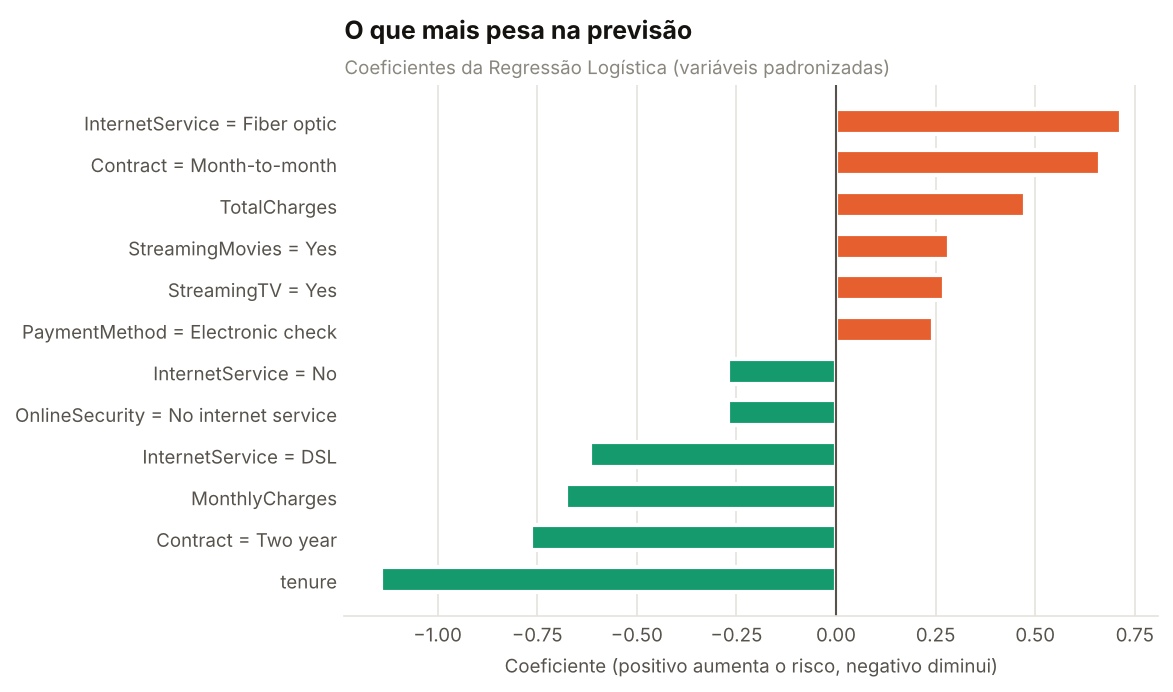

In [9]:
display(Image(FIGURES_DIR / "coeficientes.png", width=620))

Os coeficientes confirmam a análise exploratória: **contrato mensal, fibra óptica e pagamento por cheque eletrônico** aumentam o risco; **contrato de 2 anos e mais tempo de casa** diminuem.

**Cuidado ao ler sinais isolados.** `MonthlyCharges` aparece com sinal negativo, embora quem cancela pague mais. Não é contradição: a cobrança mensal é quase a soma dos serviços contratados (fibra, streaming…), que já estão no modelo. Quando variáveis são muito correlacionadas, o modelo divide o efeito entre elas e o sinal de cada uma, sozinha, deixa de ter significado claro. O mesmo vale para `TotalCharges`, que é quase `tenure × MonthlyCharges`. Para explicar o modelo ao negócio, o mais seguro é olhar **grupos de variáveis** ou o efeito no risco de mudar um perfil inteiro, como faz o simulador da página.

## 6. Limitações

- **Probabilidade não calibrada:** o `class_weight="balanced"` empurra as probabilidades para cima. O modelo é bom para **ordenar** clientes por risco, mas "80%" não quer dizer que 8 em cada 10 cancelam. Para usar como probabilidade, seria preciso calibrar (por exemplo com `CalibratedClassifierCV`).
- **Foto de um momento:** a base é de um único período. Em produção, o modelo precisaria ser monitorado e retreinado.
- **Correlação, não causa:** o modelo indica quem priorizar, não por que a pessoa vai sair.

## Próximos passos

- Calibrar as probabilidades e escolher o limiar a partir do custo real de uma ação de retenção.
- Testar variáveis novas (por exemplo, quantos serviços extras o cliente tem).
- Servir o modelo numa API para o CRM consultar em tempo real.